[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-1/blob/main/notebooks/ch01_LabCh01_What_Learning_Is.ipynb)

**The Why Book of Deep Learning, Part 1** by Dr. Philemon Paul Daniel

**Chapter 1: What Learning Really Is** (Part I: The Learning Machine).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-1/read.html?ch=1](https://www.micyaai.com/books/why-deep-learning-1/read.html?ch=1)
* The simplified video course for kids that this book grew from: [aikids.guru](https://www.aikids.guru)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)

Tested with TensorFlow 2.21 and Keras 3.14. In Colab: *Runtime > Run all*. A GPU runtime makes the bigger
models faster but none of them needs one.

---


# Lab Ch01 - What Learning Is
## A function with knobs, a number for "how wrong", and a loop that turns the knobs

This lab goes with **Chapter 1** of *The Why Book of Deep Learning*.

Chapter 1 says that a network is an adjustable function and that learning is turning its knobs
to shrink one number, the loss. In this lab you watch that happen, knob by knob, on the smallest
model there is, and then you watch the same loop fail, succeed and cheat.

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Name the four ingredients of any learning system in code | Step 3 |
| Watch a weight and a bias move epoch by epoch, and read a loss curve | Steps 4 and 5 |
| Run the predict-measure-adjust loop by hand in NumPy | Step 7 |
| Recognise a learning rate that is too large | Step 8 |
| Tell "the family is wrong" from "the search failed" | Steps 9 and 10 |
| See memorising happen, and catch it with a validation set | Steps 12 and 13 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. A wrong prediction
that you then understand teaches more than a right answer you only read.

> **Runtime:** a laptop CPU is enough; the whole notebook takes about a minute or two.
> All the data is made up on the spot (a few hundred numbers), so nothing is downloaded.

---
# Part A - One straight line, learnt

---
## Step 1 - Imports and one seed

The seed makes the random starting knobs (and the random noise later) the same on every run,
so your numbers should match the comments. Your last digit may still differ on other hardware.

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt

import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

keras.utils.set_random_seed(42)          # same numbers on every run

print("TensorFlow:", tf.__version__)
print("Keras     :", keras.__version__)

TensorFlow: 2.21.0
Keras     : 3.14.1


---
## Step 2 - The data: 200 examples of a rule we pretend not to know

The hidden rule is `y = 2x + 1`. We make 200 inputs between -1 and 1 and their right answers.
The model will only ever see these pairs, never the rule.

> **Predict:** what is the shape of `x`? Why does it have two axes and not one?

In [2]:
x = np.linspace(-1, 1, 200).reshape(-1, 1).astype("float32")
y = 2 * x + 1

print("x shape:", x.shape, "  y shape:", y.shape)
print("first three pairs:")
for i in range(3):
    print(f"   x = {x[i, 0]:+.3f}   ->   y = {y[i, 0]:+.3f}")

x shape: (200, 1)   y shape: (200, 1)
first three pairs:
   x = -1.000   ->   y = -1.000
   x = -0.990   ->   y = -0.980
   x = -0.980   ->   y = -0.960


### Why we see this

`(200, 1)`: 200 examples, each made of **one** number. Keras always wants the first axis to be
"which example" and the rest to be "what one example looks like". Chapter 2 is all about this habit.

---
## Step 3 - The four ingredients, as four named lines

Every learning system in the book has exactly four ingredients. Here they are, one line each:

| Ingredient | What it is | Here |
|---|---|---|
| data | examples with the right answers | `x`, `y` |
| model | a family of functions with knobs | one `Dense(1)`: `y = w * x + b` |
| loss | one number for "how wrong" | mean squared error |
| optimiser | a rule for turning the knobs | plain SGD, step size 0.1 |

> **Predict:** how many knobs (parameters) does `Dense(1)` on one input have?
> What values do you expect them to start at?

In [3]:
data      = (x, y)                                                       # 1. data
model     = keras.Sequential([layers.Input(shape=(1,)), layers.Dense(1)])  # 2. model
loss      = "mse"                                                        # 3. loss
optimizer = keras.optimizers.SGD(learning_rate=0.1)                      # 4. optimiser

model.compile(loss=loss, optimizer=optimizer)
model.summary()

by_hand = 1 * 1 + 1                      # 1 input x 1 unit weights + 1 bias
assert model.count_params() == by_hand == 2

w0, b0 = model.layers[0].get_weights()
print(f"\nstarting knobs: w = {w0[0, 0]:+.4f}, b = {b0[0]:+.4f}")
print(f"starting loss : {model.evaluate(x, y, verbose=0):.4f}")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 1)              │             2 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2 (8.00 B)

 Trainable params: 2 (8.00 B)

 Non-trainable params: 0 (0.00 B)


starting knobs: w = +1.2408, b = +0.0000


starting loss : 1.1941


### Why we see this

Two parameters: one weight, one bias. Keras starts the weight at a small random value and the
bias at exactly 0. The starting loss is large because a random line is far from `2x + 1`.
Training will not add knobs or change the family. It will only pick values for these two.

---
## Step 4 - Run the loop and watch the knobs move

`fit` runs the loop: predict a batch, measure the loss, work out the slope for each knob,
nudge each knob downhill, repeat. With 200 examples and batch size 32 that is 7 nudges per epoch.
A small callback records `w` and `b` at the end of every epoch so we can print them.

> **Predict:** after the **first** epoch (7 nudges), will `w` be close to 2? Which knob do you
> think settles first, `w` or `b`? How many epochs until both are right to two decimals?

In [4]:
knobs = []                               # (epoch, w, b) after each epoch
record = keras.callbacks.LambdaCallback(
    on_epoch_end=lambda epoch, logs: knobs.append(
        (epoch + 1, *[float(v.ravel()[0]) for v in model.layers[0].get_weights()])))

t0 = time.time()
history = model.fit(x, y, epochs=40, batch_size=32, verbose=0, callbacks=[record])
print(f"{len(history.epoch)} epochs in {time.time() - t0:.1f} s\n")

print(" epoch        w         b        loss")
for (epoch, w, b), l in zip(knobs, history.history["loss"]):
    if epoch <= 8 or epoch % 8 == 0:
        print(f"{epoch:>6}  {w:8.4f}  {b:8.4f}  {l:10.6f}")

40 epochs in 2.0 s

 epoch        w         b        loss
     1    1.5448    0.7875    0.557404
     2    1.7256    0.9536    0.068986
     3    1.8343    0.9892    0.019073
     4    1.8999    0.9971    0.006672
     5    1.9395    0.9990    0.002422
     6    1.9634    0.9995    0.000884
     7    1.9779    0.9998    0.000323
     8    1.9866    0.9999    0.000118
    16    1.9998    1.0000    0.000000
    24    2.0000    1.0000    0.000000
    32    2.0000    1.0000    0.000000
    40    2.0000    1.0000    0.000000


### Why we see this

The loss falls fast at first and then crawls: the chapter's "cliff, then a long shallow slide".
The bias usually settles before the weight. With inputs between -1 and 1 the bias gets a strong,
consistent push from every example, while the weight's push is weak near `x = 0` and stronger
only near the ends. Nobody told the model about 2 or 1; it found them from 200 examples.

---
## Step 5 - Plot the loss curve and the knobs

> **Predict:** on a normal axis the loss curve will look like an "L". What will it look like if
> the loss axis is logarithmic?

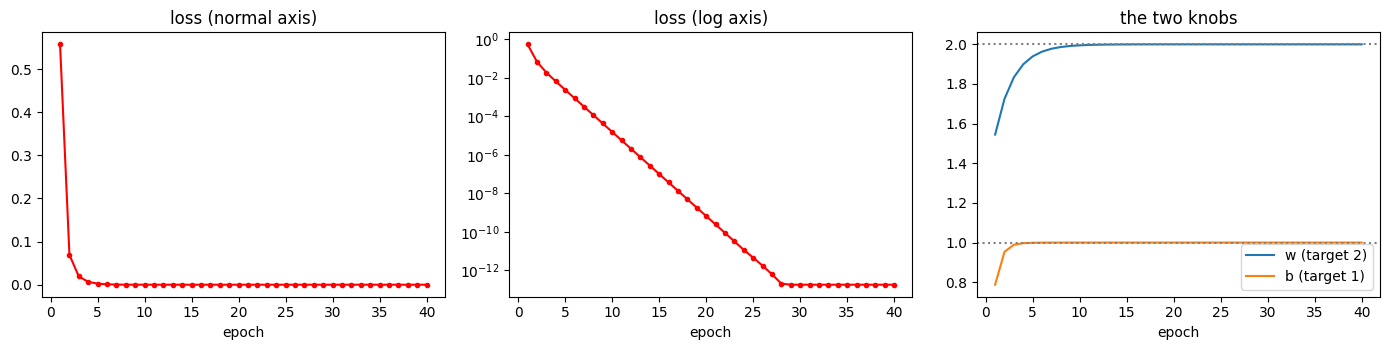

In [5]:
epochs = [k[0] for k in knobs]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6))
ax[0].plot(epochs, history.history["loss"], "r-o", ms=3)
ax[0].set_title("loss (normal axis)"); ax[0].set_xlabel("epoch")
ax[1].semilogy(epochs, history.history["loss"], "r-o", ms=3)
ax[1].set_title("loss (log axis)"); ax[1].set_xlabel("epoch")
ax[2].plot(epochs, [k[1] for k in knobs], label="w (target 2)")
ax[2].plot(epochs, [k[2] for k in knobs], label="b (target 1)")
ax[2].axhline(2, ls=":", c="grey"); ax[2].axhline(1, ls=":", c="grey")
ax[2].set_title("the two knobs"); ax[2].set_xlabel("epoch"); ax[2].legend()
plt.tight_layout(); plt.show()

### Why we see this

On a log axis the "L" becomes a nearly straight downhill line: the loss shrinks by about the same
**factor** every epoch. That is what plain gradient descent does on a bowl-shaped loss. A log axis
is how you see whether training is still making progress when the normal axis looks flat.

---
## Step 6 - Inference: the knobs are frozen

Using the trained model on new inputs is the forward pass alone: no answer, no loss, no nudge.

> **Predict:** the model never saw an `x` outside -1 to 1. What will it say for `x = 10`?

In [6]:
new_x = np.array([[0.5], [3.0], [10.0]], dtype="float32")
pred = model.predict(new_x, verbose=0)
for xi, pi in zip(new_x[:, 0], pred[:, 0]):
    print(f"x = {xi:5.1f}   model says {pi:8.4f}   rule says {2 * xi + 1:6.1f}")

w_before = model.layers[0].get_weights()[0].copy()
model.predict(new_x, verbose=0)
assert np.array_equal(w_before, model.layers[0].get_weights()[0])   # predicting changes nothing
print("\nthe knobs did not move during predict()")

x =   0.5   model says   2.0000   rule says    2.0
x =   3.0   model says   7.0000   rule says    7.0
x =  10.0   model says  21.0000   rule says   21.0

the knobs did not move during predict()


### Why we see this

It gets `x = 10` right, far outside the training range. That is luck of a special kind: the family
(straight lines) happens to contain the true rule, so the learnt line **is** the rule everywhere.
In Part B the family is wrong, and outside the training range a model can be wildly off.

---
## Step 7 - The same loop by hand, in NumPy

Keras hides the loop. Here it is with nothing hidden, on the chapter's five examples
(x = 0, 1, 2, 3, 4; answers 1, 3, 5, 7, 9), both knobs starting at 0, step size 0.05, all five
examples in every step. The slopes of the mean squared error are worked out by hand
(Chapter 7 shows where they come from).

> **Predict:** the starting loss (the chapter worked it out). Roughly how much of it is left
> after three steps?

In [7]:
X5 = np.array([0., 1., 2., 3., 4.])
Y5 = 2 * X5 + 1

def descend(lr, steps, show):
    w = b = 0.0
    print("  step        w        b        loss")
    for t in range(steps + 1):
        p = w * X5 + b                           # 1. predict (forward pass)
        L = np.mean((p - Y5) ** 2)               # 2. measure (the loss)
        if t in show:
            print(f"{t:>6}  {w:7.3f}  {b:7.3f}  {L:10.4f}")
        gw = np.mean(2 * (p - Y5) * X5)          # 3. slope of the loss for each knob
        gb = np.mean(2 * (p - Y5))               #    (the backward pass, by hand)
        w, b = w - lr * gw, b - lr * gb          #    nudge both knobs downhill
    return L                                     # 4. repeat

descend(lr=0.05, steps=200, show=[0, 1, 2, 3, 10, 50, 200])

  step        w        b        loss
     0    0.000    0.000     33.0000
     1    1.400    0.500      3.6100
     2    1.860    0.670      0.4113
     3    2.010    0.731      0.0622
    10    2.069    0.804      0.0129
    50    2.020    0.942      0.0011
   200    2.000    0.999      0.0000


np.float64(1.290717783618578e-07)

### Why we see this

33, then 3.61, then 0.41, then 0.062: three steps remove 99.8% of the loss, and the next 197
polish the bias from 0.73 to 1.00. These are the numbers printed in the chapter. Four lines inside
the loop are the whole of "learning"; every model in the book does exactly this with more knobs.

---
## Step 8 - A step that is too long

Same five examples, same start, but the step size goes from 0.05 to 0.2.

> **Predict:** four times the step size, four times as fast? Or something else?

In [8]:
descend(lr=0.2, steps=4, show=[0, 1, 2, 3, 4]);

  step        w        b        loss
     0    0.000    0.000     33.0000
     1    5.600    2.000     93.1600
     2   -3.840   -1.280    263.0928
     3   12.000    4.304    743.0764
     4  -14.643   -5.018   2098.7966


### Why we see this

The loss **climbs**: 33, 93, 263, 743, ... Each step jumps over the valley floor and lands higher
up the other wall. Nothing is wrong with the data or the model. When the loss rises from the first
step or turns into `nan`, shorten the step first. That step size is the learning rate (Chapter 8).

---
# Part B - When the family is wrong

---
## Step 9 - Ask a straight line to fit a curve

Same inputs, new answers: `y = x**2`. Same four ingredients, same loop, 100 epochs.

> **Predict:** the final `w`, the final `b` and the final loss. (Hint: the curve is symmetric
> around `x = 0`. Which straight line is "least wrong" for a U shape?)

In [9]:
def make_line():
    m = keras.Sequential([layers.Input(shape=(1,)), layers.Dense(1)])
    m.compile(loss="mse", optimizer=keras.optimizers.SGD(learning_rate=0.1))
    return m

y_sq = x ** 2
line = make_line()
h_line = line.fit(x, y_sq, epochs=100, batch_size=32, verbose=0)
w, b = [float(v.ravel()[0]) for v in line.layers[0].get_weights()]
print(f"learnt w = {w:+.3f}, b = {b:.3f}, final loss = {line.evaluate(x, y_sq, verbose=0):.4f}")
print(f"best possible line: w = 0, b = mean(y) = {y_sq.mean():.3f}, loss = var(y) = {y_sq.var():.4f}")

learnt w = +0.002, b = 0.361, final loss = 0.0913
best possible line: w = 0, b = mean(y) = 0.337, loss = var(y) = 0.0907


### Why we see this

The weight ends near 0 and the bias near 1/3: a flat line through the average height of the curve,
with a loss near 0.09 that more epochs will not reduce. The search worked perfectly: it found the
best straight line there is. The **family** contains nothing better. This is the first of the
chapter's two ways to fail, and the fix is a different model, not more training.

---
## Step 10 - One hidden layer with ReLU

Put 16 units with the ReLU activation between the input and the output. ReLU is
`max(0, z)`: each unit can contribute a bent line, and 16 bends can follow a curve. (Chapters 3 to 5
explain the neuron, the layer and the activation properly.) We use the Adam optimiser here, a
smarter step rule from Chapter 8, so the run is short; plain SGD also gets there, more slowly.

> **Predict:** the parameter count, by hand. Dense layer = inputs x units + units.
> Then predict the final loss: closer to 0.09 or closer to 0?

In [10]:
def make_bent(activation="relu", units=16):
    m = keras.Sequential([
        layers.Input(shape=(1,)),
        layers.Dense(units, activation=activation),   # the hidden layer
        layers.Dense(1),                              # the output
    ])
    m.compile(loss="mse", optimizer=keras.optimizers.Adam(learning_rate=0.01))
    return m

bent = make_bent()
by_hand = (1 * 16 + 16) + (16 * 1 + 1)
print("by hand :", by_hand, " by Keras:", bent.count_params())
assert bent.count_params() == by_hand == 49

t0 = time.time()
h_bent = bent.fit(x, y_sq, epochs=150, batch_size=32, verbose=0)
print(f"150 epochs in {time.time() - t0:.1f} s")
print(f"straight line final loss : {line.evaluate(x, y_sq, verbose=0):.6f}")
print(f"one ReLU layer final loss: {bent.evaluate(x, y_sq, verbose=0):.6f}")

by hand : 49  by Keras: 49


150 epochs in 6.9 s
straight line final loss : 0.091282
one ReLU layer final loss: 0.000010


---
## Step 11 - Look at both fits

> **Predict:** what will the ReLU model's curve look like close up: smooth, or made of straight pieces?

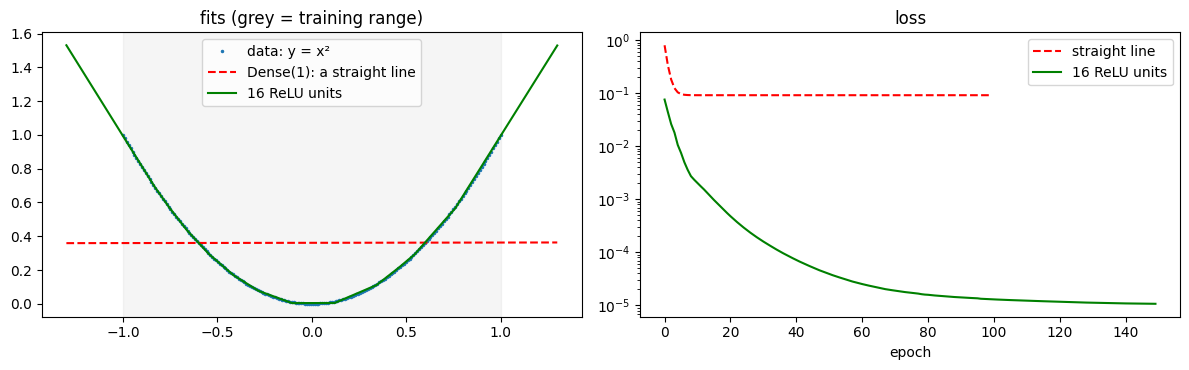

In [11]:
xs = np.linspace(-1.3, 1.3, 400).reshape(-1, 1).astype("float32")
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(x, y_sq, ".", c="tab:blue", ms=3, label="data: y = x²")
ax[0].plot(xs, line.predict(xs, verbose=0), "r--", label="Dense(1): a straight line")
ax[0].plot(xs, bent.predict(xs, verbose=0), "g-", label="16 ReLU units")
ax[0].axvspan(-1, 1, color="grey", alpha=0.08); ax[0].legend(); ax[0].set_title("fits (grey = training range)")
ax[1].semilogy(h_line.history["loss"], "r--", label="straight line")
ax[1].semilogy(h_bent.history["loss"], "g-", label="16 ReLU units")
ax[1].set_xlabel("epoch"); ax[1].set_title("loss"); ax[1].legend()
plt.tight_layout(); plt.show()

### Why we see this

The straight line is stuck at its floor near 0.09; the ReLU network keeps falling far below it.
Close up the green curve is a chain of straight segments joined at kinks, one possible kink per
hidden unit. Outside the grey training range it carries on in straight lines while the true
curve bends upwards: a network only knows the region its data covered. Remove `activation="relu"`
and the two layers collapse into a single straight line again (Trial 3 below; Chapter 5 says why).

---
# Part C - Memorising, and how to catch it

---
## Step 12 - A big model and a tiny training set

Real answers are noisy. We draw 400 noisy examples of `y = x**2` (noise with standard deviation
0.2), keep the last 200 aside as a **validation set** the loop never trains on, and give the model
only the first **10** for training. The model is far too big for 10 points: two hidden layers of
128 ReLU units.

The noise sets a floor: even the true rule `x**2` scores a mean squared error of about
0.2² = 0.04 on noisy answers.

> **Predict:** the final training loss and the final validation loss. Which one falls below
> the 0.04 floor, and what does falling below it mean?

In [12]:
rng = np.random.default_rng(0)
x_all = rng.uniform(-1, 1, (400, 1)).astype("float32")
y_all = (x_all ** 2 + rng.normal(0, 0.2, x_all.shape)).astype("float32")
x_val, y_val = x_all[200:], y_all[200:]           # never trained on
print(f"noise floor on validation (true rule's loss): {np.mean((x_val ** 2 - y_val) ** 2):.4f}")

def make_big():
    m = keras.Sequential([
        layers.Input(shape=(1,)),
        layers.Dense(128, activation="relu"),
        layers.Dense(128, activation="relu"),
        layers.Dense(1),
    ])
    m.compile(loss="mse", optimizer=keras.optimizers.Adam(learning_rate=0.003))
    return m

def train_and_score(n_train, epochs=300):
    keras.utils.set_random_seed(1)
    m = make_big()
    h = m.fit(x_all[:n_train], y_all[:n_train], validation_data=(x_val, y_val),
              epochs=epochs, batch_size=32, verbose=0)
    tr = m.evaluate(x_all[:n_train], y_all[:n_train], verbose=0)
    va = m.evaluate(x_val, y_val, verbose=0)
    return m, h, tr, va

big = make_big()
by_hand = (1 * 128 + 128) + (128 * 128 + 128) + (128 * 1 + 1)
print("parameters by hand:", by_hand, " by Keras:", big.count_params())
assert big.count_params() == by_hand == 16_897

t0 = time.time()
m10, h10, tr10, va10 = train_and_score(10)
print(f"\n10 training examples, 16,897 knobs ({time.time() - t0:.1f} s)")
print(f"   training loss  : {tr10:.4f}")
print(f"   validation loss: {va10:.4f}")

noise floor on validation (true rule's loss): 0.0413
parameters by hand: 16897  by Keras: 16897



10 training examples, 16,897 knobs (25.3 s)
   training loss  : 0.0102
   validation loss: 0.0663


### Why we see this

The training loss ends far **below** the noise floor (about a quarter of it on our run). No honest rule can do that: the only way to
score better than `x**2` itself on noisy answers is to bend through the noise of those particular
10 points, which is memorising. The validation loss, measured on examples the loop never saw, sits
well above the floor (about 0.07 against 0.04). A training score on its own would have told you the model was excellent.

---
## Step 13 - Same model, twenty times the data

Nothing changes except the training set: the first 200 examples instead of the first 10.
The validation set is the same 200 held-back examples.

> **Predict:** will the training loss go up or down? And the validation loss? Where will both end
> up compared with the 0.04 floor?

200 training examples (27.9 s)
   training loss  : 0.0383
   validation loss: 0.0409


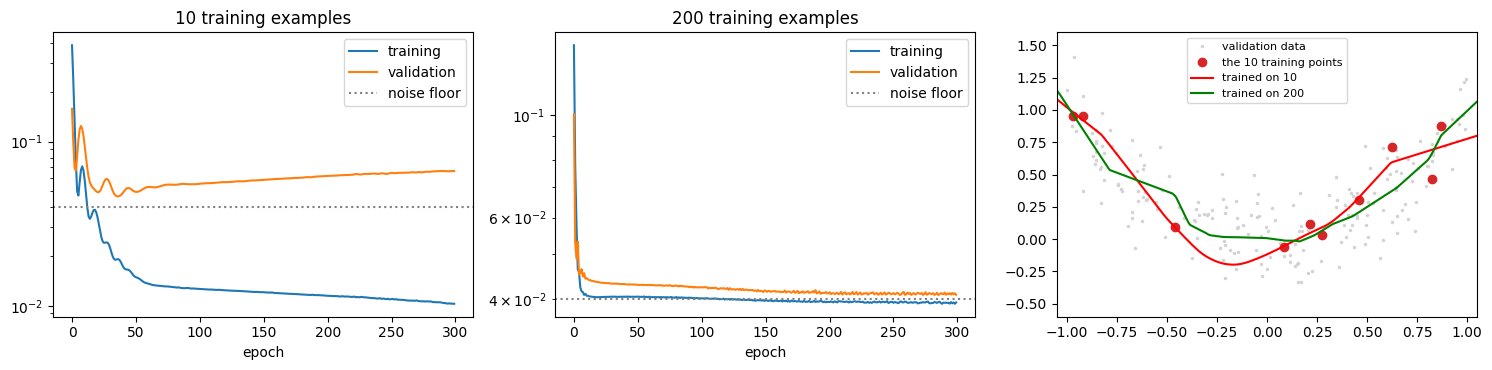

In [13]:
t0 = time.time()
m200, h200, tr200, va200 = train_and_score(200)
print(f"200 training examples ({time.time() - t0:.1f} s)")
print(f"   training loss  : {tr200:.4f}")
print(f"   validation loss: {va200:.4f}")

fig, ax = plt.subplots(1, 3, figsize=(15, 3.8))
for a, (h, n) in zip(ax[:2], [(h10, 10), (h200, 200)]):
    a.semilogy(h.history["loss"], label="training"); a.semilogy(h.history["val_loss"], label="validation")
    a.axhline(0.04, ls=":", c="grey", label="noise floor"); a.set_title(f"{n} training examples")
    a.set_xlabel("epoch"); a.legend()
ax[2].plot(x_val, y_val, ".", c="lightgrey", ms=3, label="validation data")
ax[2].plot(x_all[:10], y_all[:10], "o", c="tab:red", label="the 10 training points")
ax[2].plot(xs, m10.predict(xs, verbose=0), "r-", label="trained on 10")
ax[2].plot(xs, m200.predict(xs, verbose=0), "g-", label="trained on 200")
ax[2].set_xlim(-1.05, 1.05); ax[2].set_ylim(-0.6, 1.6); ax[2].legend(fontsize=8)
plt.tight_layout(); plt.show()

### Why we see this

With 200 examples the training loss goes **up** (to about the noise floor: the model can no longer
thread a curve through every noisy point) and the validation loss comes **down** to meet it. The
gap between the two curves is the size of the memorising. Same model, same loop; only the evidence
changed. That gap, read from two curves, is the subject of Chapter 11.

---
## Trials: change one thing at a time

Write your prediction in the table **before** you run each trial. Re-run from the step named
(and the steps after it that use its result).

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | Step 3: `SGD(learning_rate=1.5)` | faster, or does the loss climb to `nan`? | |
| 2 | Step 4: `epochs=3` | are the knobs right, nearly right, or nowhere? which kind of failure is it? | |
| 3 | Step 10: `make_bent(activation=None)` | parameter count? final loss compared with the straight line? | |
| 4 | Step 10: `make_bent(units=2)` | how many kinks can the curve have? final loss? | |
| 5 | Step 2: `y = 2 * x + 1 + np.random.normal(0, 0.3, x.shape)` | final knobs? final loss? | |
| 6 | Step 12: `train_and_score(40)` | where do training and validation loss land, between the 10 and 200 cases? | |
| 7 | Step 12: make the hidden layers 8 units each (fix the assert) | does the 10-point model still get under the floor? | |
| 8 | Step 7: `descend(lr=0.1, ...)` and `descend(lr=0.15, ...)` | which converges? where is the border? | |

## Exercises

1. **Grid search.** In NumPy, compute the loss of Step 7 for every `w` and `b` on a grid from -1 to 4
   in steps of 0.1 and find the smallest. How many loss evaluations was that? How many would a grid
   with 10 values per knob need for the 16,897 knobs of Step 12?
2. **The dictionary model.** Write a "model" that stores the 10 training points of Step 12 and, for a
   new `x`, returns the `y` of the nearest stored point. Compute its training and validation loss.
   Compare with Step 12.
3. **Accuracy is not a loss.** For Step 7, count a prediction as "correct" if it is within 0.5 of the
   answer. Print the accuracy for `w` = 1.90, 1.91, ..., 2.10 with `b = 1`. Where does it change, and
   why could an optimiser not follow it?
4. **Extrapolation.** Predict `x = 3` with the ReLU model of Step 10. The right answer is 9.
   How far off is it, and why?
5. **Batch size.** In Step 4 use `batch_size=200` (one nudge per epoch). How many epochs are needed
   now to reach the same loss? Count nudges, not epochs.

## Cheat sheet

```python
data      = (x, y)                                                       # examples + answers
model     = keras.Sequential([layers.Input(shape=(1,)), layers.Dense(1)])  # family with knobs
model.compile(loss="mse",                                                # how wrong
              optimizer=keras.optimizers.SGD(learning_rate=0.1))         # how to turn the knobs
model.fit(x, y, epochs=40, batch_size=32, validation_data=(x_val, y_val))  # the loop
model.layers[0].get_weights()                                            # look at the knobs
model.predict(new_x)                                                     # inference: knobs frozen
```

- Parameters are set by the loop; learning rate, epochs, batch size and layer sizes are set by you.
- Loss climbing from step one, or `nan`: shorten the step (learning rate).
- Loss stuck at a floor however long you train: the family is wrong; change the model.
- Training loss below the noise floor while validation loss stays high: memorising. More data,
  a smaller model, or the tools of Chapter 11.